# Book Recommender System using a Medallion Data Lake
Bronze → Silver → Gold pipeline on the Book-Crossing dataset, followed by an item-based collaborative filtering recommender.

## Step 1: Data Lake Setup and Bronze Layer

In [4]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

for folder in ["bronze", "silver", "gold", "raw"]:
    os.makedirs(folder, exist_ok=True)

ZIP_PATH = "book-crossings.zip"
if not os.path.exists(ZIP_PATH):
    urllib.request.urlretrieve("https://cdn.freecodecamp.org/project-data/books/book-crossings.zip", ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall("raw")

for root, _, files in os.walk("raw"):
    for f in files:
        print(os.path.join(root, f))

raw/BX-Users.csv
raw/BX-Book-Ratings.csv
raw/BX-Books.csv


In [5]:
def find_file(name):
    for root, _, files in os.walk("raw"):
        if name in files:
            return os.path.join(root, name)

read_args = dict(sep=";", encoding="latin-1", escapechar="\\")

users_raw = pd.read_csv(find_file("BX-Users.csv"), **read_args)
books_raw = pd.read_csv(find_file("BX-Books.csv"), **read_args)
ratings_raw = pd.read_csv(find_file("BX-Book-Ratings.csv"), **read_args)

ingestion_ts = pd.Timestamp.now()
for df in (users_raw, books_raw, ratings_raw):
    df["ingestion_timestamp"] = ingestion_ts

users_raw.to_parquet("bronze/users.parquet", index=False)
books_raw.to_parquet("bronze/books.parquet", index=False)
ratings_raw.to_parquet("bronze/ratings.parquet", index=False)

print(sorted(os.listdir("bronze")))

['books.parquet', 'ratings.parquet', 'users.parquet']


## Step 2: Exploratory Data Analysis on Bronze

In [6]:
users_b = pd.read_parquet("bronze/users.parquet")
books_b = pd.read_parquet("bronze/books.parquet")
ratings_b = pd.read_parquet("bronze/ratings.parquet")

for name, df in [("users", users_b), ("books", books_b), ("ratings", ratings_b)]:
    print(name.upper(), df.shape)
    print(df.dtypes.to_string())
    print(df.isna().sum().to_string())
    print()

USERS (278858, 4)
User-ID                         int64
Location                       object
Age                           float64
ingestion_timestamp    datetime64[us]
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0

BOOKS (271379, 9)
ISBN                           object
Book-Title                     object
Book-Author                    object
Year-Of-Publication             int64
Publisher                      object
Image-URL-S                    object
Image-URL-M                    object
Image-URL-L                    object
ingestion_timestamp    datetime64[us]
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
ingestion_timestamp    0

RATINGS (1149780, 4)
User-ID                         int64
ISBN                           object
Book-Rating               

**Shape, types, missing values:** users has 278,858 rows with 110,762 missing ages (39.7%), books has 271,379 rows with 2 missing authors and 2 missing publishers, and ratings has 1,149,780 rows with no missing values; in Silver I will fill missing ages with the median, drop books with missing key fields, and ignore the timestamp and image columns.

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
share of zeros: 62.28 %


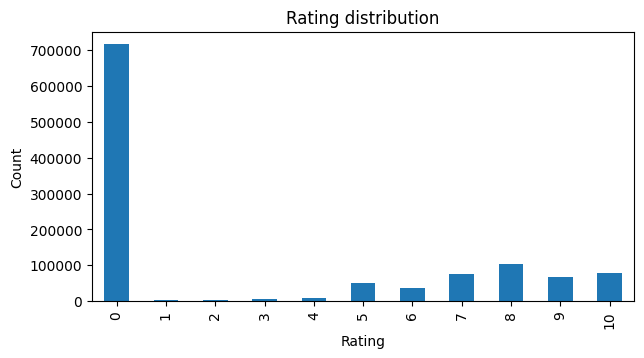

In [7]:
rating_counts = ratings_b["Book-Rating"].value_counts().sort_index()
print(rating_counts.to_string())
print("share of zeros:", round((ratings_b["Book-Rating"] == 0).mean() * 100, 2), "%")

rating_counts.plot(kind="bar", figsize=(7, 3.5), title="Rating distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

**Ratings distribution:** 716,109 of 1,149,780 ratings (62.3%) are 0, which only means no explicit rating, so in Silver I will drop all zeros and keep ratings 1 to 10.

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
ages below 5 or above 100: 1248
count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
year == 0: 4619
year in the future: 11
year between 1 and 1499: 2


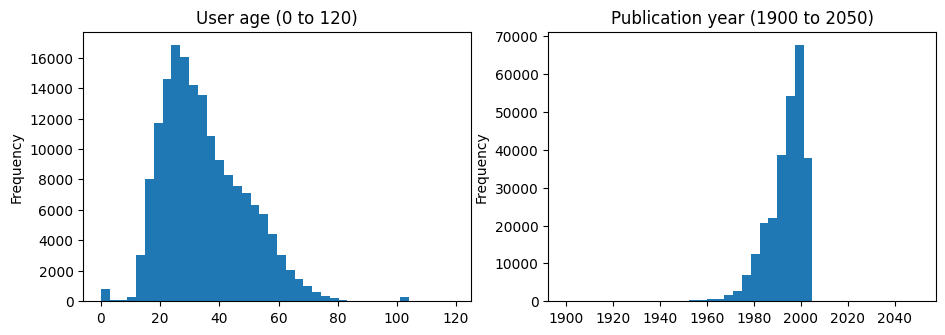

In [8]:
age = users_b["Age"]
print(age.describe().to_string())
print("ages below 5 or above 100:", ((age < 5) | (age > 100)).sum())

year = books_b["Year-Of-Publication"]
print(year.describe().to_string())
print("year == 0:", (year == 0).sum())
print("year in the future:", (year > datetime.now().year).sum())
print("year between 1 and 1499:", ((year > 0) & (year < 1500)).sum())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
age[(age >= 0) & (age <= 120)].plot(kind="hist", bins=40, ax=ax[0], title="User age (0 to 120)")
year[(year >= 1900) & (year <= 2050)].plot(kind="hist", bins=40, ax=ax[1], title="Publication year (1900 to 2050)")
plt.show()

**User ages:** ages range from 0 to 244 and 1,248 known values fall outside 5 to 100, so in Silver I will null those and fill with the median age.

**Publication years:** 4,619 books have year 0, 11 have future years up to 2050 and 2 are earlier than 1500, so in Silver I will set these impossible years to null.

count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
users with fewer than 10 ratings: 87.56 %
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
books with fewer than 10 ratings: 94.62 %


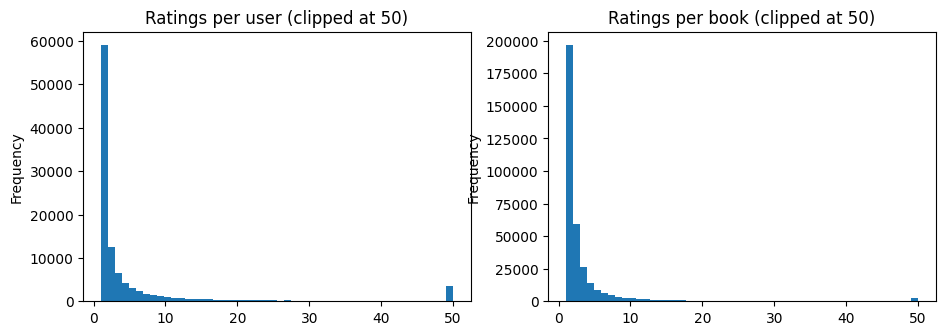

In [9]:
per_user = ratings_b.groupby("User-ID").size()
per_book = ratings_b.groupby("ISBN").size()

print(per_user.describe().to_string())
print("users with fewer than 10 ratings:", round((per_user < 10).mean() * 100, 2), "%")
print(per_book.describe().to_string())
print("books with fewer than 10 ratings:", round((per_book < 10).mean() * 100, 2), "%")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
per_user.clip(upper=50).plot(kind="hist", bins=50, ax=ax[0], title="Ratings per user (clipped at 50)")
per_book.clip(upper=50).plot(kind="hist", bins=50, ax=ax[1], title="Ratings per book (clipped at 50)")
plt.show()

**Ratings per user and per book:** the median is 1 rating for both, 87.6% of users and 94.6% of books have fewer than 10 ratings, so in Silver I will keep only users and books above a minimum rating count.

In [10]:
n_users = ratings_b["User-ID"].nunique()
n_books = ratings_b["ISBN"].nunique()
n_ratings = len(ratings_b)
density = n_ratings / (n_users * n_books)
print("users:", n_users, "books:", n_books, "ratings:", n_ratings)
print("density: %.5f %%" % (density * 100))
print("sparsity: %.5f %%" % ((1 - density) * 100))

explicit = ratings_b[ratings_b["Book-Rating"] > 0]
pu = explicit.groupby("User-ID").size()
pb = explicit.groupby("ISBN").size()
print("explicit ratings:", len(explicit), "users:", len(pu), "books:", len(pb))
for t in (5, 10, 20, 50):
    print("min", t, "-> users:", (pu >= t).sum(), "books:", (pb >= t).sum())

users: 105283 books: 340556 ratings: 1149780
density: 0.00321 %
sparsity: 99.99679 %
explicit ratings: 433671 users: 77805 books: 185973
min 5 -> users: 14220 books: 14535
min 10 -> users: 7334 books: 5645
min 20 -> users: 3704 books: 2179
min 50 -> users: 1332 books: 537


**Matrix sparsity:** only about 0.003% of possible user-book pairs have a rating (99.997% empty), so Gold will store the matrix in sparse format.

**Threshold choice:** after dropping zeros, a minimum of 10 ratings leaves 7,334 users and 5,645 books, which is dense enough for cosine similarity to be meaningful while keeping a few thousand items; a threshold of 5 keeps many noisy items and 20 or more discards too much, so I use 10 for both users and books.

## Step 3: Silver Layer

In [11]:
MIN_RATINGS = 10
CURRENT_YEAR = datetime.now().year

def clean_text(s):
    s = s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    return s

users = pd.read_parquet("bronze/users.parquet").drop(columns=["ingestion_timestamp"])
books = pd.read_parquet("bronze/books.parquet").drop(columns=["ingestion_timestamp"])
ratings = pd.read_parquet("bronze/ratings.parquet").drop(columns=["ingestion_timestamp"])

print("before:", len(users), len(books), len(ratings))

users = users.drop_duplicates().drop_duplicates(subset="User-ID")
books = books.drop_duplicates()
books["ISBN"] = clean_text(books["ISBN"]).str.upper()
books = books.drop_duplicates(subset="ISBN")
ratings["ISBN"] = clean_text(ratings["ISBN"]).str.upper()
ratings = ratings.drop_duplicates().drop_duplicates(subset=["User-ID", "ISBN"], keep="last")

print("after duplicates:", len(users), len(books), len(ratings))

before: 278858 271379 1149780
after duplicates: 278858 271064 1149780


In [12]:
ratings = ratings[ratings["Book-Rating"].between(1, 10)].copy()
print("ratings after removing zeros:", len(ratings))

users["Age"] = users["Age"].where(users["Age"].between(5, 100))
users["Age"] = users["Age"].fillna(users["Age"].median())

loc = clean_text(users["Location"]).str.lower().str.split(",", expand=True)
loc = loc.apply(lambda c: clean_text(c))
users["city"] = loc[0]
users["country"] = loc.ffill(axis=1).iloc[:, -1]
users["state"] = loc[1].where(loc[2].notna()) if loc.shape[1] > 2 else pd.NA
for c in ["city", "state", "country"]:
    users[c] = users[c].replace({"": pd.NA, "n/a": pd.NA})
users = users.drop(columns=["Location"]).rename(columns={"User-ID": "user_id", "Age": "age"})

books["Year-Of-Publication"] = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
bad_year = (books["Year-Of-Publication"] == 0) | (books["Year-Of-Publication"] > CURRENT_YEAR) | (books["Year-Of-Publication"] < 1500)
books["Year-Of-Publication"] = books["Year-Of-Publication"].mask(bad_year).astype("Int64")

books = books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])
for c in ["Book-Title", "Book-Author", "Publisher"]:
    books[c] = clean_text(books[c]).str.title().str.replace(r"'S\b", "'s", regex=True).str.replace("&Amp;", "&", regex=False)
books = books.dropna(subset=["Book-Title"])
books = books.rename(columns={
    "ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
    "Year-Of-Publication": "year", "Publisher": "publisher"})
ratings = ratings.rename(columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})

print(users.head().to_string())
print(books.head().to_string())
print(users["age"].describe().to_string())
print(books["year"].isna().sum(), "null years")

ratings after removing zeros: 433671
   user_id   age         city         country            state
0        1  32.0          nyc             usa         new york
1        2  18.0     stockton             usa       california
2        3  32.0       moscow          russia  yukon territory
3        4  17.0        porto        portugal         v.n.gaia
4        5  32.0  farnborough  united kingdom            hants
         isbn                                                                                               title                author  year                publisher
0  0195153448                                                                                 Classical Mythology    Mark P. O. Morford  2002  Oxford University Press
1  0002005018                                                                                        Clara Callan  Richard Bruce Wright  2001    Harperflamingo Canada
2  0060973129                                                                       

In [13]:
ratings = ratings[ratings["user_id"].isin(users["user_id"]) & ratings["isbn"].isin(books["isbn"])]
print("ratings with valid user and book:", len(ratings))

while True:
    before = len(ratings)
    uc = ratings.groupby("user_id")["rating"].transform("size")
    ratings = ratings[uc >= MIN_RATINGS]
    bc = ratings.groupby("isbn")["rating"].transform("size")
    ratings = ratings[bc >= MIN_RATINGS]
    if len(ratings) == before:
        break

users = users[users["user_id"].isin(ratings["user_id"])].reset_index(drop=True)
books = books[books["isbn"].isin(ratings["isbn"])].reset_index(drop=True)
ratings = ratings.reset_index(drop=True)

print("silver users:", len(users), "books:", len(books), "ratings:", len(ratings))
print("min ratings per user:", ratings.groupby("user_id").size().min())
print("min ratings per book:", ratings.groupby("isbn").size().min())

users.to_parquet("silver/users.parquet", index=False)
books.to_parquet("silver/books.parquet", index=False)
ratings.to_parquet("silver/ratings.parquet", index=False)
print(sorted(os.listdir("silver")))

ratings with valid user and book: 383853
silver users: 1820 books: 2030 ratings: 41469
min ratings per user: 10
min ratings per book: 10
['books.parquet', 'ratings.parquet', 'users.parquet']


## Step 4: Gold Layer

In [14]:
users_s = pd.read_parquet("silver/users.parquet")
books_s = pd.read_parquet("silver/books.parquet")
ratings_s = pd.read_parquet("silver/ratings.parquet")

user_ids = np.sort(ratings_s["user_id"].unique())
isbns = np.sort(ratings_s["isbn"].unique())
user_map = pd.Series(np.arange(len(user_ids)), index=user_ids)
book_map = pd.Series(np.arange(len(isbns)), index=isbns)

rows = ratings_s["user_id"].map(user_map).to_numpy()
cols = ratings_s["isbn"].map(book_map).to_numpy()
rating_matrix = sparse.csr_matrix(
    (ratings_s["rating"].to_numpy(dtype=np.float32), (rows, cols)),
    shape=(len(user_ids), len(isbns)))

sparse.save_npz("gold/rating_matrix.npz", rating_matrix)
pd.DataFrame({"user_idx": user_map.values, "user_id": user_map.index}).to_parquet("gold/user_index.parquet", index=False)
pd.DataFrame({"book_idx": book_map.values, "isbn": book_map.index}).to_parquet("gold/book_index.parquet", index=False)

book_lookup = books_s[["isbn", "title", "author"]].rename(columns={"isbn": "book_id"})
book_lookup["book_idx"] = book_lookup["book_id"].map(book_map)
book_lookup = book_lookup.sort_values("book_idx").reset_index(drop=True)
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

user_stats = ratings_s.groupby("user_id")["rating"].agg(avg_rating="mean", n_ratings="size").reset_index()
book_stats = ratings_s.groupby("isbn")["rating"].agg(avg_rating="mean", n_ratings="size").reset_index()
user_stats.to_parquet("gold/user_stats.parquet", index=False)
book_stats.to_parquet("gold/book_stats.parquet", index=False)

print("matrix shape (users x books):", rating_matrix.shape)
print("non-zero entries:", rating_matrix.nnz)
print("sparsity: %.3f %%" % ((1 - rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1])) * 100))
print(sorted(os.listdir("gold")))
print(book_lookup.head().to_string())
print(user_stats.head().to_string())
print(book_stats.head().to_string())

matrix shape (users x books): (1820, 2030)
non-zero entries: 41469
sparsity: 98.878 %
['book_index.parquet', 'book_lookup.parquet', 'book_stats.parquet', 'rating_matrix.npz', 'user_index.parquet', 'user_stats.parquet']
      book_id                                                                        title               author  book_idx
0  0020199600                                                       Great Gatsby (Reissue)  F. Scott Fitzgerald         0
1  0020442203                                             Lion, The Witch And The Wardrobe           C.S. Lewis         1
2  002542730X     Politically Correct Bedtime Stories: Modern Tales For Our Life And Times    James Finn Garner         2
3  0028604199  Once Upon A More Enlightened Time: More Politically Correct Bedtime Stories    James Finn Garner         3
4  0060002050                                            On A Wicked Dawn (Cynster Novels)    Stephanie Laurens         4
   user_id  avg_rating  n_ratings
0      243    7

## Step 5: Item-Based Collaborative Filtering Recommender

In [15]:
user_item = sparse.load_npz("gold/rating_matrix.npz")
user_index = pd.read_parquet("gold/user_index.parquet")
lookup = pd.read_parquet("gold/book_lookup.parquet").sort_values("book_idx").reset_index(drop=True)
book_stats_g = pd.read_parquet("gold/book_stats.parquet")

item_user = user_item.T.tocsr()
print("book x user matrix:", item_user.shape)

lookup = lookup.merge(book_stats_g.rename(columns={"isbn": "book_id"}), on="book_id", how="left")
lookup["title_key"] = lookup["title"].str.lower()
lookup["base_key"] = (lookup["title"].str.lower()
                      .str.replace(r"\(.*?\)", "", regex=True)
                      .str.split(":").str[0]
                      .str.replace(r"[^a-z0-9 ]", "", regex=True)
                      .str.replace(r"\s+", " ", regex=True).str.strip())
title_keys = lookup["base_key"].to_numpy()
user_row = pd.Series(user_index["user_idx"].values, index=user_index["user_id"].values)

knn = NearestNeighbors(metric="cosine", algorithm="brute")
knn.fit(item_user)

book x user matrix: (2030, 1820)


NearestNeighbors(algorithm='brute', metric='cosine')

In [16]:
def find_book_idx(title):
    key = title.strip().lower()
    exact = lookup[lookup["title_key"] == key]
    if exact.empty:
        exact = lookup[lookup["title_key"].str.contains(key, regex=False)]
    if exact.empty:
        raise ValueError("Book not found: " + title)
    return int(exact.sort_values("n_ratings", ascending=False)["book_idx"].iloc[0])

def similar_books(title, n=10):
    idx = find_book_idx(title)
    dist, neigh = knn.kneighbors(item_user[idx], n_neighbors=min(n * 3 + 1, item_user.shape[0]))
    out = lookup.iloc[neigh[0]][["title", "author"]].copy()
    out["similarity"] = 1 - dist[0]
    query_title = lookup.loc[idx, "title"]
    out = out[(out.index != idx) & (out["title"] != query_title)]
    out = out.drop_duplicates(subset="title").head(n)
    return out.reset_index(drop=True)

def recommend(user_id, n=10, like_threshold=7, k=50):
    if user_id not in user_row.index:
        raise ValueError("User not in Gold layer: " + str(user_id))
    row = user_item[user_row[user_id]]
    rated_idx = row.indices
    rated_val = row.data
    read = set(rated_idx.tolist())
    read_keys = {title_keys[i] for i in read}

    liked = rated_idx[rated_val >= like_threshold]
    liked_val = rated_val[rated_val >= like_threshold]
    if len(liked) == 0:
        top = np.argsort(-rated_val)[:5]
        liked, liked_val = rated_idx[top], rated_val[top]

    dist, neigh = knn.kneighbors(item_user[liked], n_neighbors=k + 1)
    scores = {}
    for i in range(len(liked)):
        for d, j in zip(dist[i], neigh[i]):
            if j == liked[i] or j in read or title_keys[j] in read_keys:
                continue
            scores[j] = scores.get(j, 0.0) + (1 - d) * liked_val[i]

    ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    out = pd.DataFrame(ranked, columns=["book_idx", "score"])
    out = out.merge(lookup[["book_idx", "title", "author"]], on="book_idx")
    out = out.merge(lookup[["book_idx", "base_key"]], on="book_idx").drop_duplicates(subset="base_key").head(n)
    return out[["title", "author", "score"]].reset_index(drop=True)

In [17]:
popular_title = lookup.sort_values("n_ratings", ascending=False)["title"].iloc[0]
print("Books similar to:", popular_title)
print(similar_books(popular_title, 10).to_string())

Books similar to: The Lovely Bones: A Novel
                                                title           author  similarity
0  Where The Heart Is (Oprah's Book Club (Paperback))     Billie Letts    0.219241
1                                    Lucky : A Memoir     Alice Sebold    0.217959
2                                   The Da Vinci Code        Dan Brown    0.178328
3                          The Pilot's Wife : A Novel     Anita Shreve    0.176339
4                                         Good In Bed  Jennifer Weiner    0.175819
5                                  Nights In Rodanthe  Nicholas Sparks    0.170172
6                              The Pact: A Love Story     Jodi Picoult    0.168194
7                                      The Lake House  James Patterson    0.166218
8                                               Lucky     Alice Sebold    0.165055
9        White Oleander : A Novel (Oprah's Book Club)      Janet Fitch    0.154238


## Step 6: Demo and Sanity Check

In [18]:
user_stats_g = pd.read_parquet("gold/user_stats.parquet")
ratings_g = pd.read_parquet("silver/ratings.parquet").merge(
    lookup[["book_id", "title", "author"]], left_on="isbn", right_on="book_id")

candidates = user_stats_g[user_stats_g["n_ratings"].between(40, 150)]
demo_users = candidates.sample(3, random_state=42)["user_id"].tolist()

for uid in demo_users:
    print("=" * 90)
    print("USER", uid)
    liked = (ratings_g[(ratings_g["user_id"] == uid) & (ratings_g["rating"] >= 8)]
             .sort_values("rating", ascending=False)[["title", "author", "rating"]].head(10))
    print("\nBooks rated highly:")
    print(liked.to_string(index=False))
    print("\nRecommendations:")
    print(recommend(uid, n=10).to_string(index=False))

USER 30735

Books rated highly:
                                                                    title          author  rating
                                   Four To Score (A Stephanie Plum Novel) Janet Evanovich      10
                                      The Red Tent (Bestselling Backlist)   Anita Diamant      10
                             Harry Potter And The Goblet Of Fire (Book 4)   J. K. Rowling      10
                                                          Q Is For Quarry     Sue Grafton      10
                                       High Five (A Stephanie Plum Novel) Janet Evanovich      10
Tuesdays With Morrie: An Old Man, A Young Man, And Life's Greatest Lesson     Mitch Albom      10
                   P Is For Peril (Kinsey Millhone Mysteries (Hardcover))     Sue Grafton      10
         Harry Potter And The Sorcerer's Stone (Harry Potter (Paperback))   J. K. Rowling      10
               K Is For Killer (Grafton, Sue. Kinsey Millhone Mysteries.)     Sue Graf

In [19]:
for uid in demo_users:
    recs = recommend(uid, n=10)
    read_titles = set(ratings_g.loc[ratings_g["user_id"] == uid, "title"])
    print(uid, "| recommendations:", len(recs), "| already read among recs:", recs["title"].isin(read_titles).sum())

30735 | recommendations: 10 | already read among recs: 0
69697 | recommendations: 10 | already read among recs: 0
236283 | recommendations: 10 | already read among recs: 0


**Sanity check:** every demo user receives 10 recommendations and none of them is a book the user has already rated, and the suggested titles share genre or author with the books the user rated highly.